# Out-of-sample test (2024) of the replica and hybrid Pareto fronts

Every portfolio on each algorithm's Pareto front is optimised on 2023 data. This notebook evaluates those portfolios on **2024** data and shows how their Sharpe ratios change and where they move in the risk–return plane. It covers two approaches:
- the **replica** ([pymoo_rep.ipynb](pymoo_rep.ipynb)),
- the **hybrid**: HRP set encoding plus QP-optimal weights ([pymoo_hrp_hybrid.ipynb](pymoo_hrp_hybrid.ipynb)).

"Each algorithm's Pareto front" means the non-dominated set of all its final portfolios over its 10 runs, per instance. Run both notebooks above first: this one reads their saved runs.

**Data for 2024.** The authors' price archive stops in December 2023 for almost every asset, so 2024 prices come from Yahoo Finance via `yfinance`. Comparing the two sources also exposed problems in the paper's 2023 inputs:
- tickers whose security changed (for example BTCI, BTCL and APLU only start trading in mid-2024),
- reverse splits that were not adjusted (the paper's data gives BITI +580 % in 2023; adjusted, it fell 67 %),
- a few series that belong to a different security (the paper's ABCB trades at about $150, Ameris Bancorp at about $47).

The optimisers favour exactly these assets, because the broken series look like high returns. As a result, many front portfolios hold assets that could not be bought as specified at the start of 2024.

**Method.**
1. An asset is *tradeable* if Yahoo has a complete history for it in both 2023 and 2024.
2. Each portfolio drops its untradeable assets and rescales the remaining weights to sum to 1. It is kept only if at least `MIN_COVERAGE` (80 %) of its original weight is tradeable.
3. Both years are measured with the **same source and the same pipeline as the authors' 2023 files**: calendar-daily closes, forward-filled; daily log returns; return = sum of the log returns; risk = $\sqrt{250\, w^\top \Sigma w}$. Applied to their own IB prices, this pipeline reproduces their published 2023 files exactly.
4. The Sharpe change 2023 → 2024 therefore reflects the out-of-sample year alone. The front *as optimised* (on the paper's 2023 data) is drawn for reference.

## 1. Settings

In [1]:
import logging
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from scipy import stats

from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

INSTANCES = [
    "NYSE_5_100", "NASDAQ_5_100", "OTC_5_100", "AMEX_5_100", "ARCA_5_100", "BATS_5_100", "ALL_5_100",
    "ALL_20_100", "ALL_20_500", "ALL_20_1000", "ALL_20_3000", "ALL_20_6000",
]
ALGORITHMS = ["MOEA/D", "SMS-EMOA", "NSGA-II"]
APPROACHES = {"replica": "Replica", "hybrid": "Hybrid (HRP set + QP weights)"}
N_RUNS = 10
BASE_EVALS = 50_000
EVAL_MULTIPLIER = {"ALL_20_500": 2, "ALL_20_1000": 3, "ALL_20_3000": 4, "ALL_20_6000": 5}
RISK_FREE = 0.0697     # the paper's Rf, used for both years
TRADING_DAYS = 250
MIN_COVERAGE = 0.80    # keep portfolios with at least this share of their weight in tradeable assets
DISTORTED = 0.10       # flag assets whose 2023 log return in the paper's data differs from Yahoo's by more than this

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROCESSED, FIGURES = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

COLORS = {"NSGA-II": "#2a78d6", "MOEA/D": "#eb6834", "SMS-EMOA": "#1baf7a"}  # same as pymoo_rep.ipynb
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.spines.top": False, "axes.spines.right": False,
})
logging.getLogger("yfinance").setLevel(logging.CRITICAL)

## 2. The Pareto fronts

For each approach, instance and algorithm, the non-dominated portfolios over its 10 runs. Replica solutions store the paper's real-valued pointers, which are decoded with the paper's linear probing. Hybrid solutions store asset ids directly.

In [2]:
def n_evals(instance):
    return int(BASE_EVALS * EVAL_MULTIPLIER.get(instance, 1))


def cache_path(approach, instance, algorithm):
    slug = algorithm.replace("/", "").replace("-", "")
    prefix = "pymoo" if approach == "replica" else f"pymoo-{approach}"
    return PROCESSED / f"{prefix}_{instance}_{slug}_{n_evals(instance)}evals.csv"


def decode_pointers(S, n_assets):
    """The paper's decoding: asset floor(s * N), linear probing on collisions."""
    n, k = S.shape
    rows = np.arange(n)
    taken = np.zeros((n, n_assets), dtype=bool)
    assets = np.empty((n, k), dtype=int)
    for j in range(k):
        c = np.minimum((S[:, j] * n_assets).astype(int), n_assets - 1)
        clash = taken[rows, c]
        while clash.any():
            c[clash] = (c[clash] + 1) % n_assets
            clash = taken[rows, c]
        taken[rows, c] = True
        assets[:, j] = c
    return assets


universe, paper_return = {}, {}
for inst in INSTANCES:
    mu = pd.read_csv(RAW / f"{inst}_mean_return.csv", index_col=0).iloc[:, 0]
    universe[inst] = np.array([s.rsplit("\\", 1)[-1].removeprefix("Day_") for s in mu.index])
    paper_return.update(dict(zip(universe[inst], mu.to_numpy())))

fronts = {}
for approach in APPROACHES:
    for inst in INSTANCES:
        for alg in ALGORITHMS:
            df = pd.read_csv(cache_path(approach, inst, alg))
            df = df[df["run"] < N_RUNS]
            df = df.iloc[NonDominatedSorting().do(df[["risk", "neg_return"]].to_numpy(), only_non_dominated_front=True)]
            if approach == "replica":
                A = decode_pointers(df.filter(regex=r"^s\d+$").to_numpy(), len(universe[inst]))
            else:
                A = df.filter(regex=r"^a\d+$").to_numpy().astype(int)
            fronts[approach, inst, alg] = {"F": df[["risk", "neg_return"]].to_numpy(), "assets": universe[inst][A],
                                           "W": df.filter(regex=r"^w\d+$").to_numpy()}

needed = sorted({t for f in fronts.values() for t in np.unique(f["assets"])})
print(f"{sum(len(f['F']) for f in fronts.values())} front portfolios holding {len(needed)} distinct assets")

41664 front portfolios holding 1266 distinct assets


## 3. Prices for 2023 and 2024 (Yahoo Finance)

Interactive Brokers symbols are mapped to Yahoo's conventions: `ANG.PRB` → `ANG-PB`, `CHEB.WS` → `CHEB-WT`, `CHEB.U` → `CHEB-UN` and `AGM.A` → `AGM-A`. Closes are split-adjusted, not dividend-adjusted, which is the same price basis as the authors' data. They are cached in `data/raw/yahoo_close_2023_2024.csv` so later runs do not depend on Yahoo revising its data.

In [3]:
def to_yahoo(ticker):
    t = re.sub(r"\.PR([A-Z]?)$", lambda m: "-P" + m.group(1), ticker)
    return t.replace(".WS", "-WT").replace(".U", "-UN").replace(".RT", "-RI").replace(".", "-")


PRICES = RAW / "yahoo_close_2023_2024.csv"
yahoo = {t: to_yahoo(t) for t in needed}
close = pd.read_csv(PRICES, index_col=0, parse_dates=True) if PRICES.exists() else pd.DataFrame()
missing = sorted(set(yahoo.values()) - set(close.columns))
for i in range(0, len(missing), 150):
    chunk = missing[i : i + 150]
    df = yf.download(chunk, start="2023-01-01", end="2025-01-01", auto_adjust=False, progress=False, threads=True)
    close = pd.concat([close, df["Close"].reindex(columns=chunk)], axis=1)
    print(f"downloaded {i + len(chunk)} of {len(missing)} tickers")
if missing:
    close.sort_index().to_csv(PRICES)
close = close.sort_index()


def complete_year(series, year):
    s = series.loc[str(year)].dropna()
    return (len(s) >= 240 and s.index[0] <= pd.Timestamp(f"{year}-01-06")
            and s.index[-1] >= pd.Timestamp(f"{year}-12-20"))


tradeable = [t for t in needed if yahoo[t] in close and complete_year(close[yahoo[t]], 2023)
             and complete_year(close[yahoo[t]], 2024)]
print(f"{len(tradeable)} of {len(needed)} assets have complete Yahoo histories for 2023 and 2024")

926 of 1266 assets have complete Yahoo histories for 2023 and 2024


**Statistics per year.** This is the authors' pipeline from `GenerarArchivosEstadisticos_JMetal.py`, applied to the tradeable assets one year at a time.

In [4]:
def year_statistics(prices, year):
    """Total log return and daily covariance per asset, computed exactly as the authors' 2023 files."""
    px = prices.loc[f"{year}-01-01":f"{year}-12-31"].resample("D").last().ffill()
    r = np.log1p(px.pct_change(fill_method=None)).replace([np.inf, -np.inf], np.nan)
    return r.sum().to_numpy(), r.ffill().bfill().cov().to_numpy()


panel = close[[yahoo[t] for t in tradeable]]
year_stats = {year: year_statistics(panel, year) for year in (2023, 2024)}
position = {t: i for i, t in enumerate(tradeable)}

# assets whose 2023 return in the paper's data disagrees with Yahoo (unadjusted splits, wrong series, ...)
yahoo_2023 = dict(zip(tradeable, year_stats[2023][0]))
distorted = {t for t in tradeable if abs(paper_return[t] - yahoo_2023[t]) > DISTORTED}
print(f"{len(distorted)} tradeable assets have a 2023 return in the paper's data that is off by more than {DISTORTED}")

92 tradeable assets have a 2023 return in the paper's data that is off by more than 0.1


## 4. Evaluating every front portfolio

In [5]:
def evaluate(idx, W, year):
    mu, cov = year_stats[year]
    ret = np.sum(W * mu[idx], axis=1)
    risk = np.sqrt(TRADING_DAYS * np.einsum("ni,nij,nj->n", W, cov[idx[:, :, None], idx[:, None, :]], W))
    return risk, ret


parts = []
for (approach, inst, alg), f in fronts.items():
    idx = np.vectorize(lambda t: position.get(t, -1))(f["assets"])
    ok = idx >= 0
    coverage = np.sum(f["W"] * ok, axis=1)
    W = np.where(ok, f["W"], 0.0) / np.maximum(coverage, 1e-12)[:, None]
    idx = np.where(ok, idx, 0)
    part = pd.DataFrame({
        "approach": approach, "instance": inst, "algorithm": alg, "coverage": coverage,
        "distorted weight": np.sum(f["W"] * np.isin(f["assets"], list(distorted)), axis=1),
        "risk opt": f["F"][:, 0], "return opt": -f["F"][:, 1],
    })
    for year in (2023, 2024):
        part[f"risk {year}"], part[f"return {year}"] = evaluate(idx, W, year)
    parts.append(part)
portfolios = pd.concat(parts, ignore_index=True)
for col in ("opt", "2023", "2024"):
    portfolios[f"Sharpe {col}"] = (portfolios[f"return {col}"] - RISK_FREE) / portfolios[f"risk {col}"]
portfolios["evaluated"] = portfolios["coverage"] >= MIN_COVERAGE
evaluated = portfolios[portfolios["evaluated"]]

coverage_table = portfolios.groupby(["instance", "approach"]).agg(
    portfolios=("coverage", "size"),
    evaluated=("evaluated", "sum"),
    median_tradeable_weight=("coverage", "median"),
    median_distorted_weight=("distorted weight", "median"),
).reindex(pd.MultiIndex.from_product([INSTANCES, APPROACHES]))
coverage_table.style.format({"median_tradeable_weight": "{:.0%}", "median_distorted_weight": "{:.0%}"}) \
    .set_caption(f"Front portfolios evaluated (at least {MIN_COVERAGE:.0%} of their weight tradeable in 2024); "
                 "distorted weight = weight on assets whose 2023 return in the paper's data is wrong")

## 5. New positions in the risk–return plane

In each panel:
- the **dashed line** is the approach's front *as optimised* on the paper's 2023 data (all three algorithms),
- the **grey dots** are the evaluated portfolios on Yahoo's 2023 data, after rescaling,
- the **coloured dots** are the same portfolios in **2024**, coloured by algorithm.

`n` is the number of portfolios evaluated.

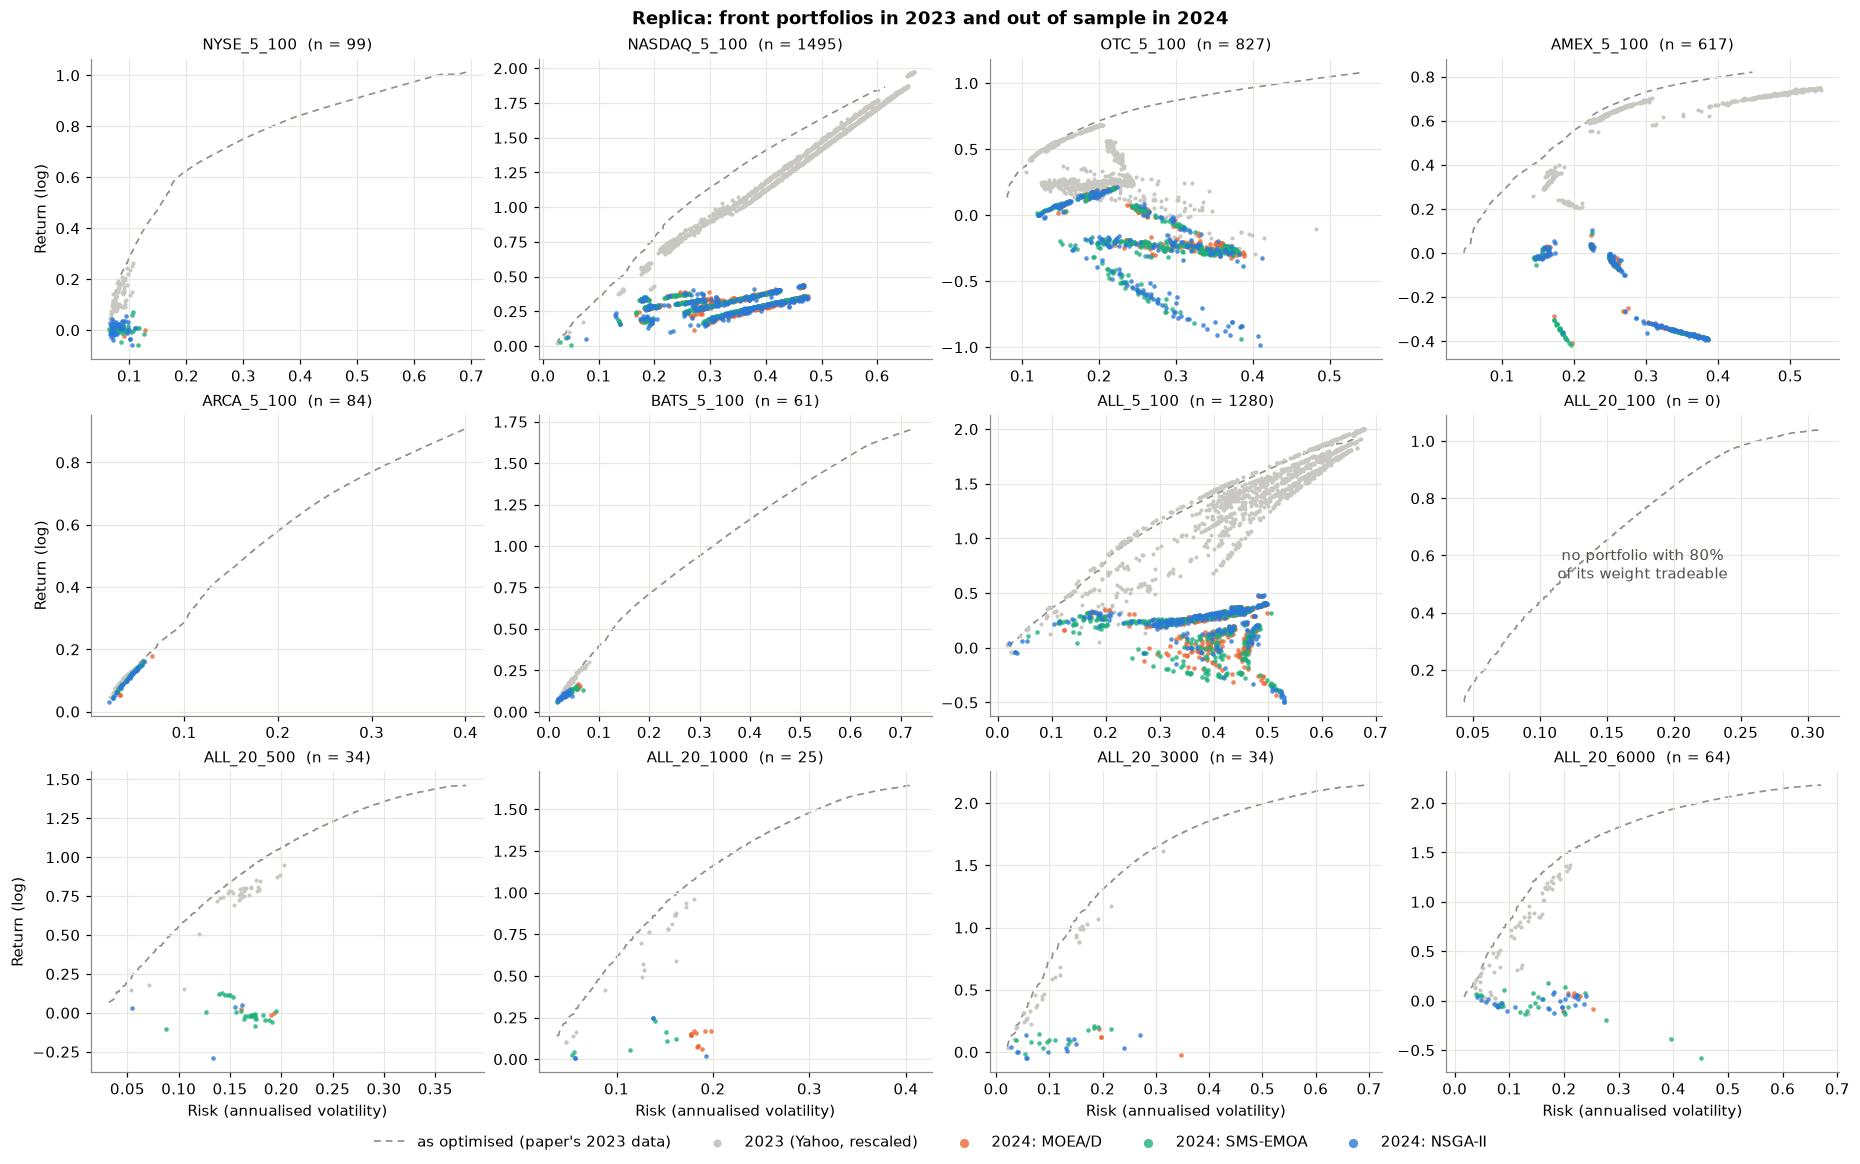

In [6]:
def instance_grid():
    ncols = 4
    nrows = int(np.ceil(len(INSTANCES) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.5 * nrows), constrained_layout=True, squeeze=False)
    for ax in axes.flat[len(INSTANCES):]:
        ax.set_visible(False)
    return fig, axes


def finish(fig, axes, xlabel, ylabel, title, filename, ncols=5):
    for ax in axes[-1]:
        ax.set_xlabel(xlabel)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    handles, labels = {}, {}
    for ax in axes.flat:
        for h, l in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(l, h)
    fig.legend(handles.values(), handles.keys(), loc="outside lower center", ncols=ncols, frameon=False, markerscale=2)
    fig.suptitle(title, fontweight="bold")
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    plt.show()


def plot_positions(approach):
    fig, axes = instance_grid()
    for ax, inst in zip(axes.flat, INSTANCES):
        opt = np.vstack([fronts[approach, inst, alg]["F"] for alg in ALGORITHMS])
        opt = opt[NonDominatedSorting().do(opt, only_non_dominated_front=True)]
        opt = opt[np.argsort(opt[:, 0])]
        ax.plot(opt[:, 0], -opt[:, 1], color="#8f8e88", ls=(0, (4, 3)), lw=1.1, zorder=1,
                label="as optimised (paper's 2023 data)")
        sub = evaluated[(evaluated["approach"] == approach) & (evaluated["instance"] == inst)]
        ax.scatter(sub["risk 2023"], sub["return 2023"], s=7, color="#c8c7c1", linewidth=0, zorder=2,
                   label="2023 (Yahoo, rescaled)")
        for alg in ALGORITHMS:
            s = sub[sub["algorithm"] == alg]
            ax.scatter(s["risk 2024"], s["return 2024"], s=9, color=COLORS[alg], linewidth=0, alpha=0.8, zorder=3,
                       label=f"2024: {alg}")
        ax.set_title(f"{inst}  (n = {len(sub)})", fontsize=10)
        if sub.empty:
            ax.text(0.5, 0.5, f"no portfolio with {MIN_COVERAGE:.0%}\nof its weight tradeable",
                    transform=ax.transAxes, ha="center", va="center", color="#52514e")
    finish(fig, axes, "Risk (annualised volatility)", "Return (log)",
           f"{APPROACHES[approach]}: front portfolios in 2023 and out of sample in 2024",
           f"oos_2024_positions_{approach}.png")


plot_positions("replica")

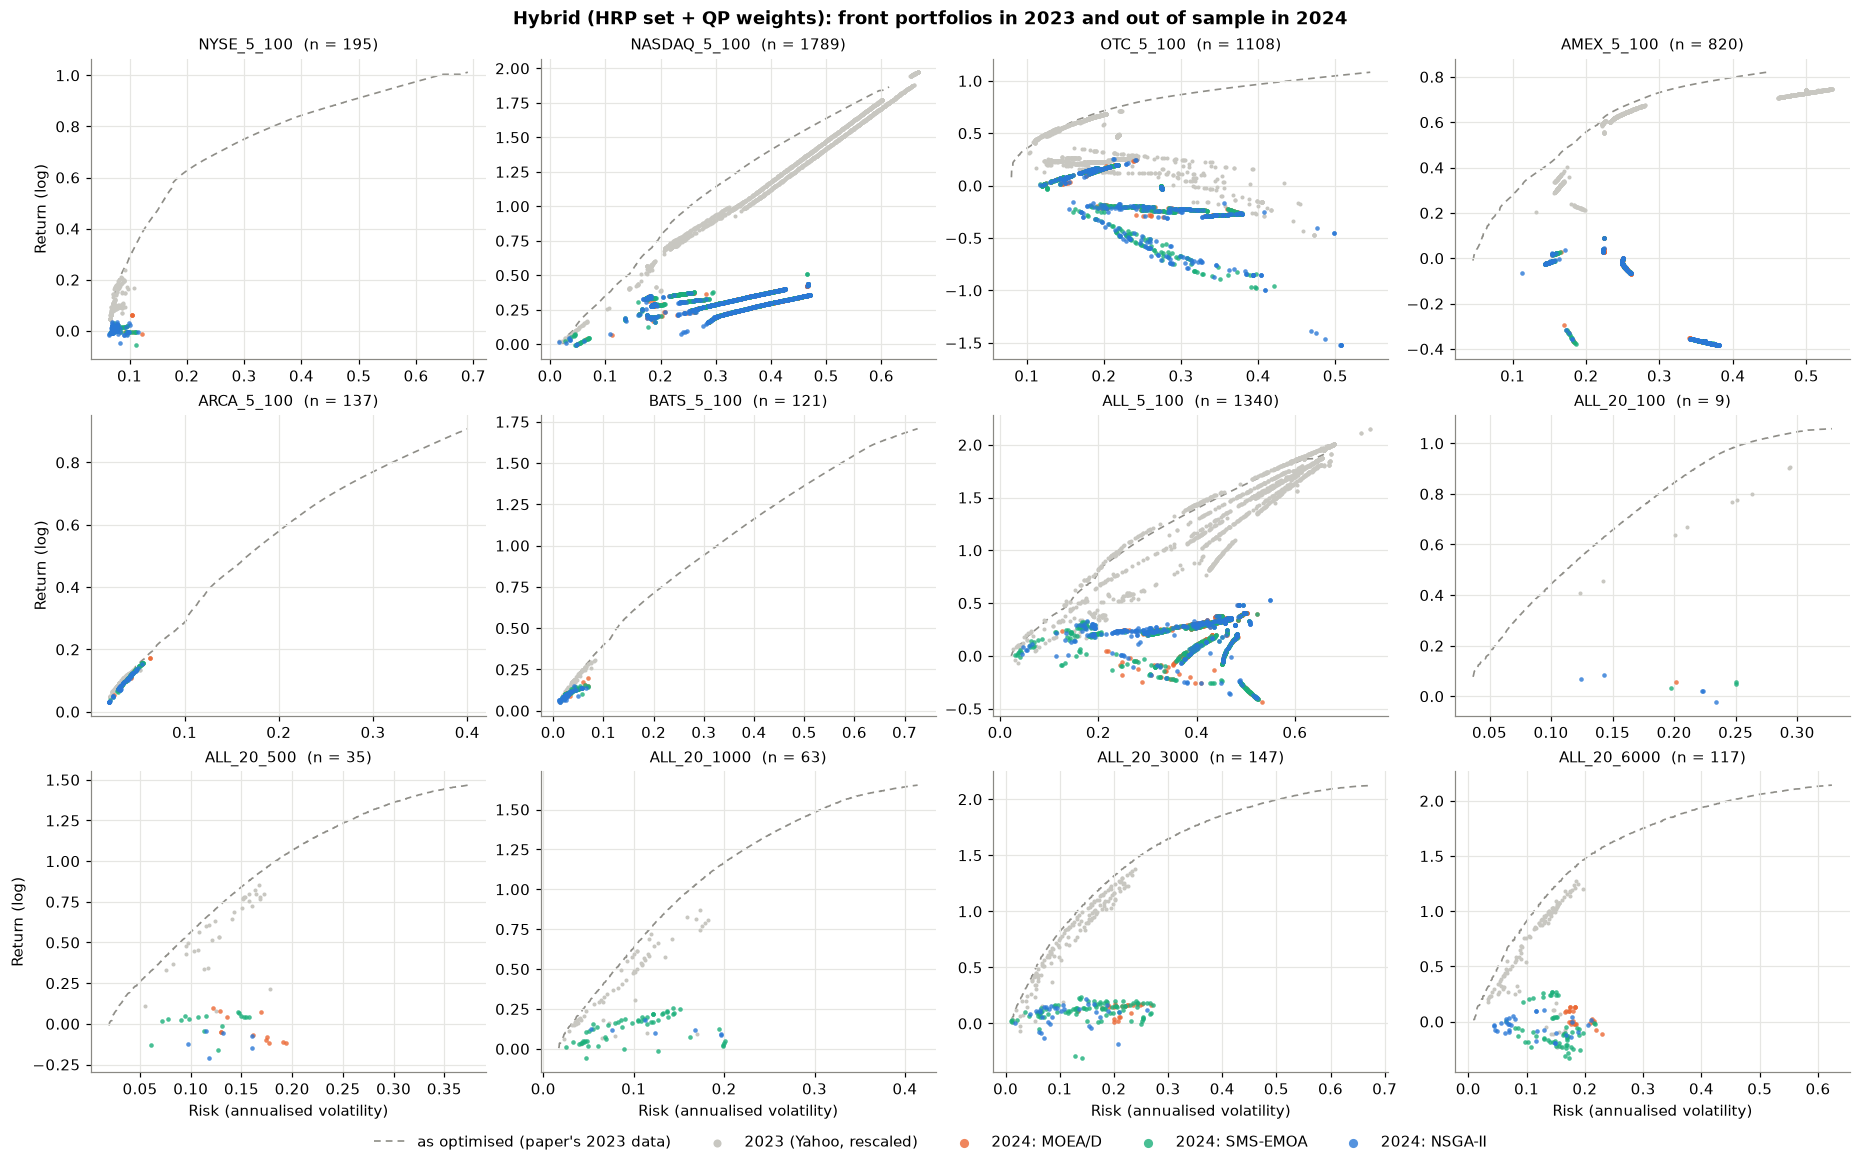

In [7]:
plot_positions("hybrid")

## 6. Sharpe ratio, 2023 vs 2024

Each dot is one evaluated portfolio, with its Sharpe ratio on 2023 data (x) and in 2024 (y), both computed with $R_f = 6.97\,\%$. Dots below the dashed diagonal lost Sharpe ratio out of sample.

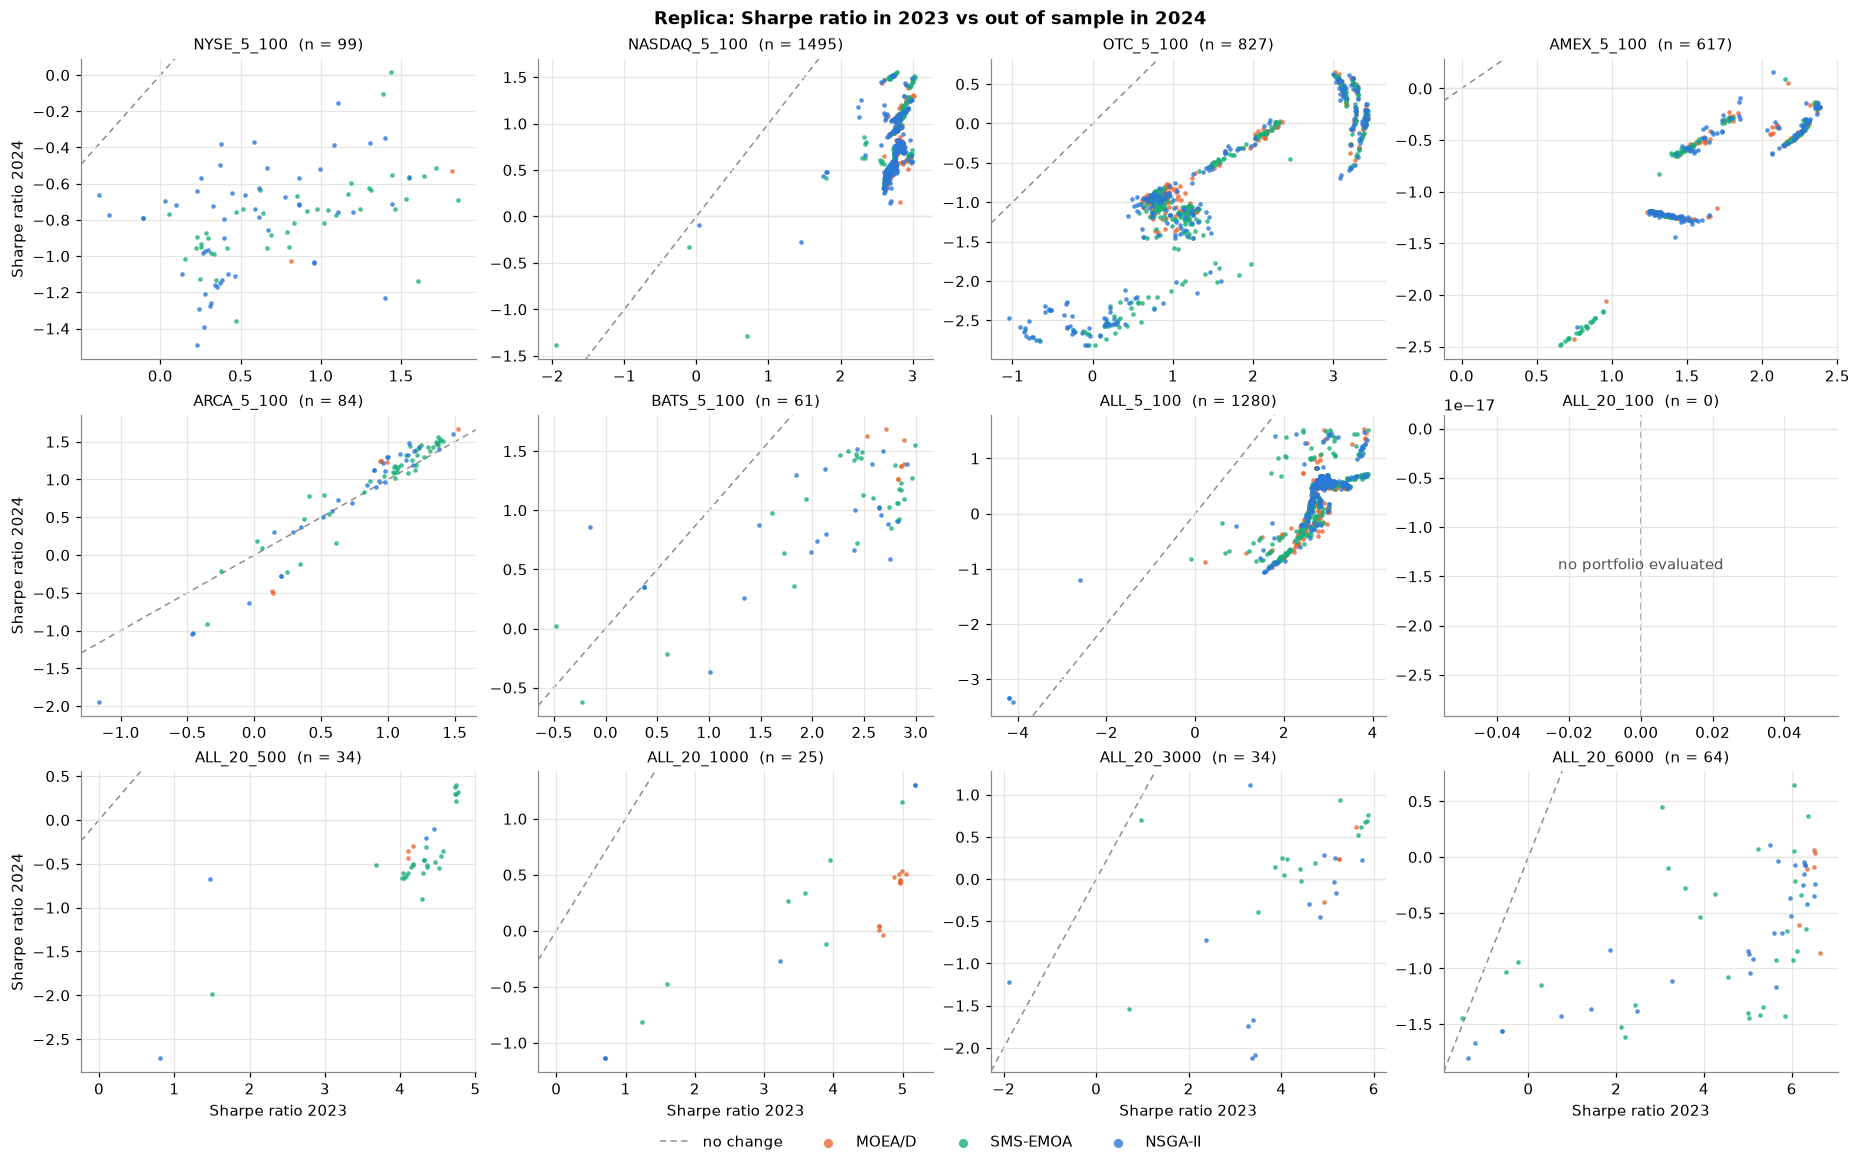

In [8]:
def plot_sharpe(approach):
    fig, axes = instance_grid()
    for ax, inst in zip(axes.flat, INSTANCES):
        sub = evaluated[(evaluated["approach"] == approach) & (evaluated["instance"] == inst)]
        ax.axline((0, 0), slope=1, color="#8f8e88", ls=(0, (4, 3)), lw=1, zorder=1, label="no change")
        ax.axhline(0, color="#c8c7c1", lw=0.8, zorder=1)
        for alg in ALGORITHMS:
            s = sub[sub["algorithm"] == alg]
            ax.scatter(s["Sharpe 2023"], s["Sharpe 2024"], s=9, color=COLORS[alg], linewidth=0, alpha=0.8, zorder=2,
                       label=alg)
        ax.set_title(f"{inst}  (n = {len(sub)})", fontsize=10)
        if sub.empty:
            ax.text(0.5, 0.5, "no portfolio evaluated", transform=ax.transAxes, ha="center", va="center", color="#52514e")
    finish(fig, axes, "Sharpe ratio 2023", "Sharpe ratio 2024",
           f"{APPROACHES[approach]}: Sharpe ratio in 2023 vs out of sample in 2024", f"oos_2024_sharpe_{approach}.png", ncols=4)


plot_sharpe("replica")

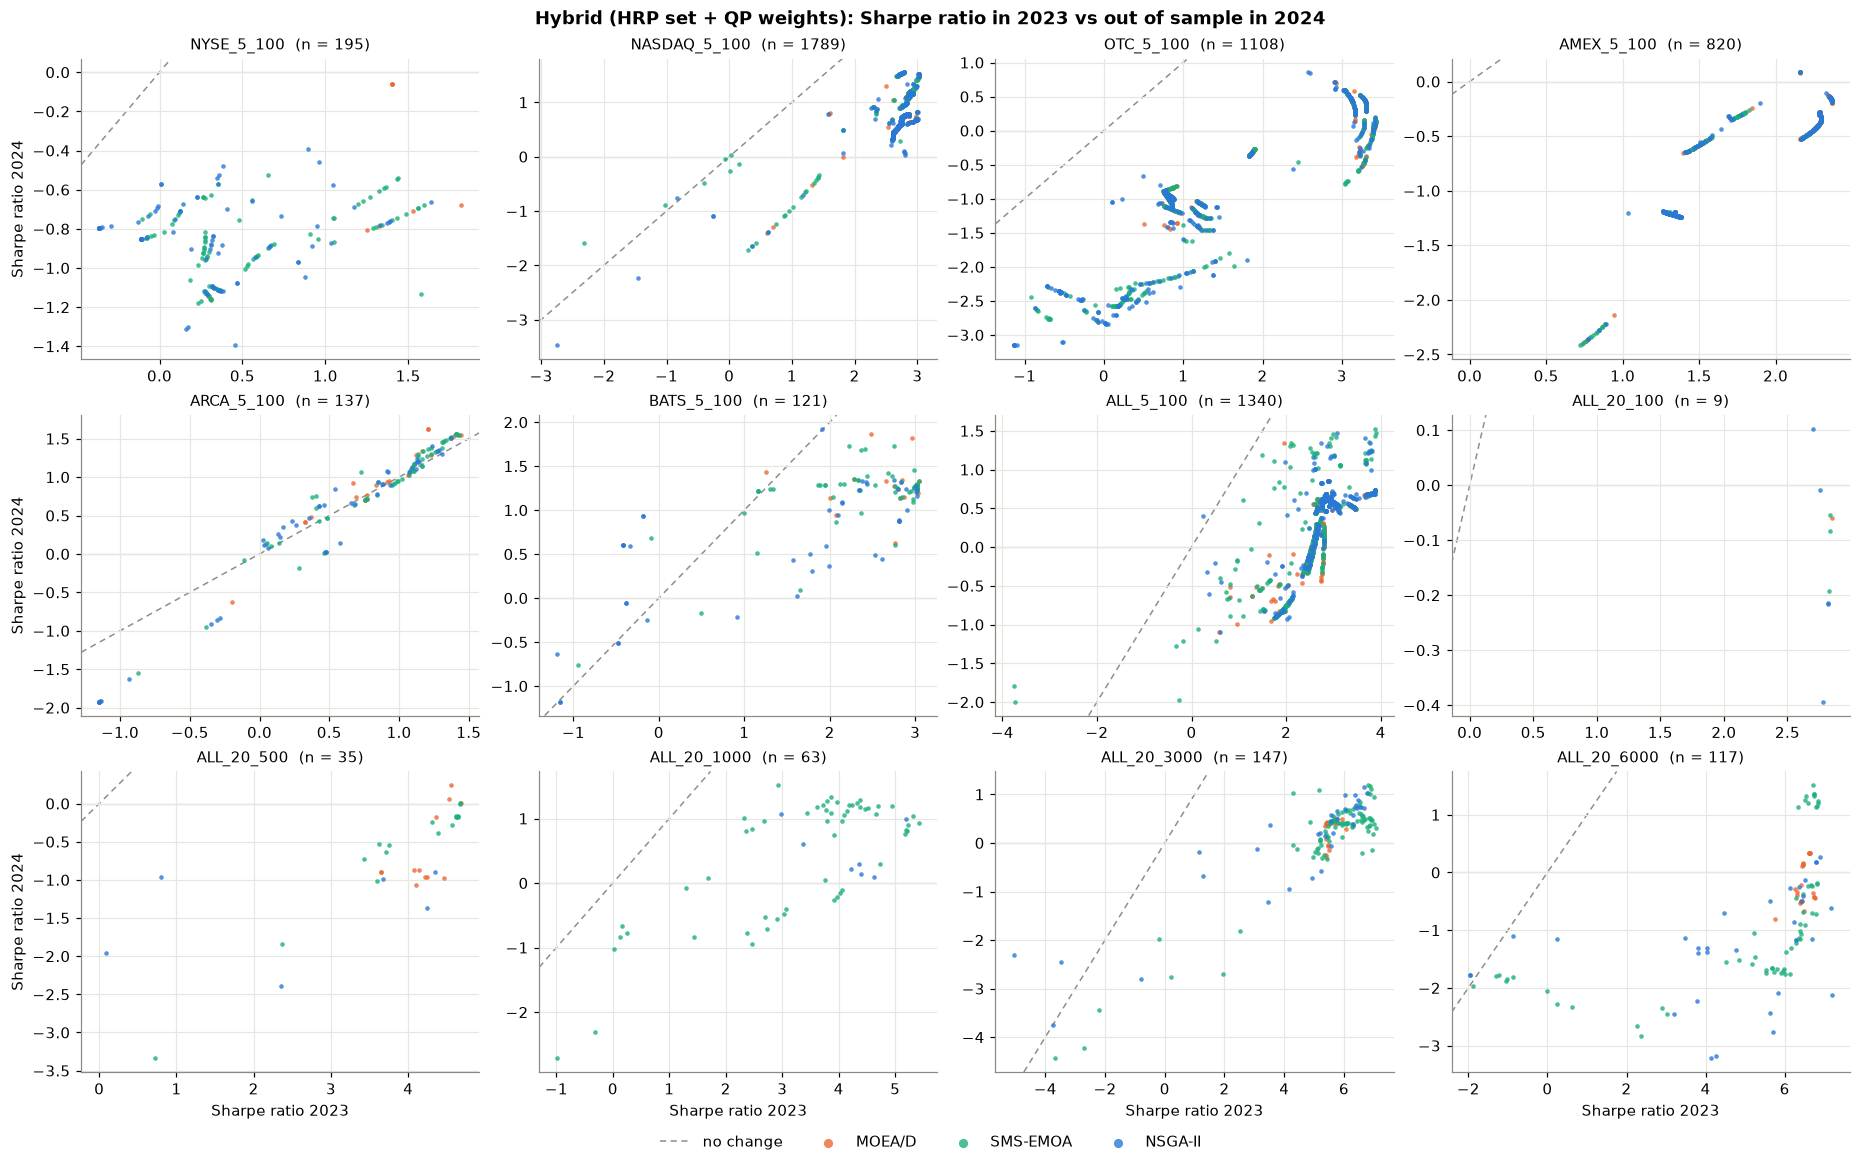

In [9]:
plot_sharpe("hybrid")

**Summary per instance.** For each instance and approach, over the evaluated portfolios:
- the median Sharpe ratio as optimised, on Yahoo's 2023 data, and in 2024, plus the median change 2023 → 2024 and the share of portfolios whose Sharpe ratio fell,
- *Spearman*: the rank correlation between 2023 and 2024 Sharpe ratios, i.e. whether the portfolios that looked best in 2023 stayed best,
- *best-2023 → 2024*: the 2024 Sharpe ratio of the portfolio with the best 2023 Sharpe ratio.

In [10]:
def summarise(g):
    if len(g) < 2:
        return pd.Series({"n": len(g)})
    best = g.loc[g["Sharpe 2023"].idxmax()]
    return pd.Series({
        "n": len(g),
        "median Sharpe as optimised": g["Sharpe opt"].median(),
        "median Sharpe 2023": g["Sharpe 2023"].median(),
        "median Sharpe 2024": g["Sharpe 2024"].median(),
        "median change": (g["Sharpe 2024"] - g["Sharpe 2023"]).median(),
        "share that fell": (g["Sharpe 2024"] < g["Sharpe 2023"]).mean(),
        "Spearman 2023 vs 2024": stats.spearmanr(g["Sharpe 2023"], g["Sharpe 2024"]).statistic,
        "best-2023 -> 2024": best["Sharpe 2024"],
    })


cols = ["n", "median Sharpe as optimised", "median Sharpe 2023", "median Sharpe 2024", "median change",
        "share that fell", "Spearman 2023 vs 2024", "best-2023 -> 2024"]
by_instance = (evaluated.groupby(["instance", "approach"]).apply(summarise, include_groups=False)
               .reindex(pd.MultiIndex.from_product([INSTANCES, APPROACHES]))[cols])
by_instance.style.format({c: "{:.2f}" for c in cols[1:]} | {"n": "{:.0f}", "share that fell": "{:.0%}"}, na_rep="–") \
    .set_caption("Sharpe ratio of the evaluated front portfolios")

In [11]:
pooled_cols = cols[:6]  # rank correlation and best portfolio only make sense within one instance
by_algorithm = (evaluated.groupby(["approach", "algorithm"]).apply(summarise, include_groups=False)
                .reindex(pd.MultiIndex.from_product([APPROACHES, ALGORITHMS]))[pooled_cols])
by_algorithm.style.format({c: "{:.2f}" for c in pooled_cols[1:]} | {"n": "{:.0f}", "share that fell": "{:.0%}"}, na_rep="–") \
    .set_caption("Pooled over all instances, per approach and algorithm")

## 7. Summary

**Coverage limits what can be tested.** Of the 1,266 assets held on the fronts, 926 have complete Yahoo histories for 2023 and 2024. Portfolios with at least 80 % of their weight in those assets are:
- 59–75 % of the front portfolios on NASDAQ_5_100 and ALL_5_100,
- 31–41 % on OTC_5_100 and AMEX_5_100,
- 3–8 % on NYSE, ARCA and BATS,
- 0–15 % on the 20-asset instances.

On the thinly covered instances, the results describe a small and possibly unrepresentative part of each front. The untested portfolios are the ones heavy in delisted or broken assets, so the full fronts would probably have done *worse* in 2024 than what is shown here.

**The Sharpe ratio collapses out of sample.**
- **How often:** apart from ARCA_5_100, 87–100 % of the evaluated portfolios on each instance have a lower Sharpe ratio in 2024 than in 2023, and 97–100 % everywhere except the hybrid on BATS_5_100. Pooled over instances, the median falls from about 2.7 to 0.3–0.5, a median change of about −2.2.
- **Where:** in the risk–return plane the portfolios keep a similar or lower risk, but their 2024 log returns fall mostly to between −0.5 and +0.5, with a few down to −1.0. The 2023 fronts reach up to about 2.0.
- **5-asset instances (median Sharpe 2023 → 2024):**
  - NASDAQ_5_100: 2.75 → 0.62 (replica), 2.77 → 0.74 (hybrid)
  - ALL_5_100: 2.77 → 0.51 and 2.76 → 0.53
  - AMEX_5_100: 1.55 → −0.57 and 1.58 → −0.52
  - OTC_5_100: 1.09 → −0.93 and 1.18 → −0.94
- **20-asset instances:** medians of 2.8–6.3 in 2023 end between −0.9 and +0.8 in 2024.
- **The only exception** is ARCA_5_100, with 84 and 137 portfolios evaluated. Its low-risk portfolios roughly keep their Sharpe ratio (1.00 → 1.13 and 0.89 → 0.92), and only 26–39 % fell.

**Rankings partly survive.** The rank correlation between 2023 and 2024 Sharpe ratios is positive on every instance (Spearman 0.13–0.98, mostly 0.5–0.9). The one exception is the hybrid on ALL_20_100, with only 9 portfolios. Portfolios that looked better in 2023 tended to stay *relatively* better. The level, however, collapses: the single best 2023 portfolio ends 2024 with a Sharpe ratio between −2.1 and +1.7.

**The hybrid's in-sample advantage does not carry over.** Its 2024 median Sharpe ratio beats the replica's on 6 of the 11 instances where both can be compared (NASDAQ, AMEX, BATS, ALL_5_100, ALL_20_1000, ALL_20_3000) and trails on 5 (NYSE, OTC, ARCA, ALL_20_500, ALL_20_6000). Pooled per algorithm, the two approaches are practically identical. Better-optimised weights on 2023 data buy no visible out-of-sample edge.

**Why.**
- *Data errors:* the front portfolios hold a median 0–26 % of their weight in assets whose 2023 return in the paper's data is wrong. That is part of the gap between the Sharpe ratio *as optimised* and the one on Yahoo's 2023 data.
- *Estimation error:* even with correct data, a single year's realised mean returns are a poor forecast of the next year's. The optimisers concentrate on 2023's winners, many of them small or volatile names, and these did not repeat in 2024.
- *Risk-free rate:* the paper's $R_f$ of 6.97 % is above 2024 T-bill yields of about 5 %. This lowers the Sharpe ratios in both years, but it is not what drives the change.